<a href="https://colab.research.google.com/github/jh2697-jiayi/damped-oscillator-simulation/blob/main/share_price_visualisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NST IA Scientific Computing Session 2: Publication Quality Graphics

The second session of the course focusses on producing high quality or “publication quality” scientific graphics. You should first work through the tasks given below.

We actively encourage you to work with your colleagues and discuss the material - however your submission must be your own work. If you get stuck or don’t understand something, ask the demonstrators for help, but you should make sure you have thought about the problem yourself, first.

# Reading data from a comma separated value (CSV) data file

**CSV Text Data Files**

In Scientific Computing, we very often end up with data from an experiment or simulation in a data file. There are many types of data files, but the simplest and most universal data files are **plain text files**, which just contain a series of characters, usually arranged into rows and columns, with **column entries separated by a particular character**.

**Comma separated value (CSV)** files are such files where numbers are separated **by a comma character, “,”**.

The following shows an example of the contents of a CSV file:

```
# This is the contents of a plain text file
# Lines marked with comment symbol
0, 1, 0
1, 2, 1
2, 3, 4
3, 4, 9
4, 5, 16
```

Very often such files have a few lines of information describing the contents of the file, before the main data starts.  These 'comment lines' are marked with a hash symbol, "#", in the above example.

CSV files sometimes have filenames that finish in `.csv`, `.txt` or `.dat`.  You can open a text file to examine the contents by loading it into a text editor such as 'Notepad', or even a word-processor like 'Pages' or 'Word'.

\


**Loading CSV Data Files into Scientific Python**

There are many ways that we can load our data into Python, so we can work on it - which is a process sometimes known as ‘importing’ the data. Here, we will use one of the commands available in NumPy, called `numpy.genfromtext()`, which is an easy way to load in a 'rectangular' block of data.

When we run the `genfromtxt()` command, it reads in the data from a text file, and creates a numpy array representing the data.  We need to specify several arguments to the command:

* The **filename** of the data file we want to import.
* The **delimiter** character, which separates the columns of data - in our case it is a comma, ","
* Any **header rows** that we want to skip at the beginning of the file (e.g. rows that are comments).

In fact, there are many other parameters that be adjusted when calling `genfromtxt()` - you can read about them [here](https://numpy.org/doc/stable/reference/generated/numpy.genfromtxt.html) if you are interested.  (For example, you can specify how to deal with missing values, or set the output datatype, etc.)

The following shows how `numpy.genfromtxt()` is used:

```
# First import NumPy
import numpy as np

# Load in data from the CSV file
exp01 = np.genfromtxt('experiment01.dat', delimiter=',', skip_header=2)
```

In this example, the code would load in data from a CSV file called `experiment01.dat` and stores the data in a NumPy array called `exp01`.

\

**Using Data Files in Google Colab**

Before we can use data files in Colab, we first have to upload them into the Colab runtime environment:

1. **Click the file icon** on the left hand side of the webpage to open a file browser on the Colab page.

2. **Click the upload icon** (or right click in the file list and choose "Upload") then you can select the file that you want to upload to Colab.

3. **Make sure that the file appears** in the file list.  You can rename the file by right clicking on the relevant file and choosing `Rename File`.

Once the file is listed correctly, you can use the `genfromtxt()` command to import the data as an array, to work on.  Remember, Python can only work on variables, so even though the file appears in the file-list, you still need to import the data.

Uploaded files only persist in Colab until your Runtime disconnects, so if you come back to your work later, you will need to re-upload your file.  (There are ways to access files on a more permanent basis, but we won't cover them today.)

\

**Now try reading in a file for yourself:**

1. Locate the file `example.dat` which is available on Moodle and **put a copy of `example.dat` in your Colab workspace**.  You will need to download the file to your computer first, then upload it to Colab.  (**Note, if you are using Safari on a Mac**: Make sure you save the file as 'Page Source', rather than a '.webarchive' file, and do not append .txt to the filename.) \
The file contains 3 columns of data from a particular simulation of atomic motion.\
The three columns are time (in ns), position (in nm) and mean position (in nm), respectively.

2. Double click the file in the Colab file list - is should open and you can **inspect the data**.\
Which are the header lines, and which lines contain data?\
Think about what rules you could use to tell someone else how to distinguish header lines from the data (there are several ways).

3. By following the example above, **use the `genfromtxt()` command to import** the contents of the data file into Python, in the empty code block below.

4. Add code to **create three new variables** corresponding to the three columns of data that you have just imported, called `a`, `b`, and `c`, respectively. You will need to use the **indexing** technique that we introduced last week (you may want to refer back to your Colab Workbook from that session).

5. Check that the contents of your variables `a`, `b`, and `c` are consistent with the original data file (i.e. compare a little of their contents with the contents of the file).


In [2]:
# This code cell is empty, ready for you to complete the above tasks in it
import numpy as np
data = np.genfromtxt('example.dat.txt', delimiter=',', skip_header=2)
a = data[:, 0]
b = data[:, 1]
c = data[:, 2]

print(a[:5])
print(b[:5])
print(c[:5])






[2016.8 2016.7 2016.6 2016.5 2016.4]
[788.97 742.98 730.87 668.43 693.14]
[158.06 158.32 160.65 152.19 153.  ]


# Plotting High Quality Figures


After loading a set of data, we very often wish to visualise the information it contains.  Within Scientific Python, we can use a series of commands to plot our data in exactly the way we want it to be displayed.  By using commands, rather than a 'point and click' interface, we can develop code that we can use again later, and we can re-run it automatically, if we need to.

\

**Basic Plotting**

We are going to start by generating 2D line plots, using the **matplotlib.pyplot** package.  As usual, we need to start by importing the `matplotlib.pyplot` package before we can use it:
```
import matplotlib.pyplot as plt
```
We could have called the imported module anything we liked, but it is conventional to refer to it as `plt`.

We can then produce a line plot by calling the `plt.plot()` function and supplying arrays containing the $x$ and $y$ coordinates of the points along the line we want to plot.  We then need to call `plt.show()` to actually display the result properly.

For example:

```
x = np.linspace(0,10,10)   # create an array of x points
y = 2*x + 3                # calculate an array of y values
plt.plot(x,y)              # create a simple plot
plt.show()                 # display the plot
```

will plot the straight line graph $y=2x+3$ between $x=0$ and $x=10$.

To add additional lines to the figure, simply add appropriate `plt.plot()` commands before calling `plt.show()`.  For example:

```
plt.plot(x,y)
plt.plot(x,2*y)
plt.show()
```

We also need to label the axes of our plot and often want to add a title, which we can do as follows:

```
plt.xlabel('Text for the x-axis label')
plt.ylabel('Text for the y-axis label')
plt.title('Text for the figure title')
```

\

The following code cell shows a real example. **Try editing and re-running the code cell, to change the gradient and intercept of the lines.**



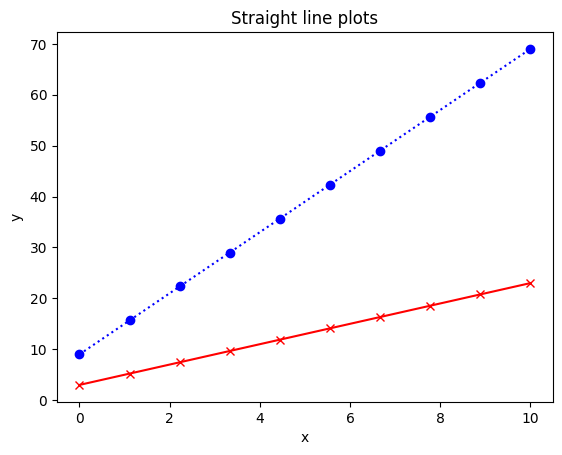

In [8]:
# Import NumPy and matplotlib.pyplot
import numpy as np
import matplotlib.pyplot as plt

# Calculate x- and y-coordinates
x = np.linspace(0,10,10)
y = 2*x + 3

# Plot lines and show the figure
plt.plot(x,y,'x-r')
plt.plot(x,3*y,'o:b')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Straight line plots')
plt.show()

Once we have generated a basic figure, we usually want to adjust the details of the it, so the data is presented exactly the way we want it, so we can make it as clear as possible.

\

**Line styles, point markers and colour** can be adjusted for each individual line that you plot.  Remember, each line consists of a series of line-segments that join the list of co-ordinates that you give to the `plot()` command.  You can control the marker used at each point (or whether there is one or not), the type of line used to join the points, and the colour of the line, by providing a format string of the form

```
fmt = '[marker][line][color]'
```
to the plot command.  For example, `plt.plot(x,y,'-r')`, would generate a solid red line, while `plt.plot(x,y,'o:b')` would produce a dotted line, with points marked by circles, in blue.

Some example of **marker** types:

* `'.'` small point marker
* `'o'` circle
* `'x'` cross marker
* `'*'` star marker
* `'^'` triangle_up marker
* `'s'` 	square marker

Some example of **Line syle** types:

* `'-'` solid line style
* `'--'` dashed line style
* `'-.'` dash-dot line style
* `':'` dotted line style

Some example of **colour marker** types:

* `'b'` 	blue
* `'g'` 	green
* `'r'` 	red
* `'c'` 	cyan
* `'m'` 	magenta

A full list of the different format types [is available here](https://matplotlib.org/3.3.2/api/_as_gen/matplotlib.pyplot.plot.html) in the matplotlib online documentation.

\

**Now, try changing the code cell above** to change the colour and linetypes of the lines that are plotted, and to add markers to the points.

\

**Adjusting the ranges** of the axes is important, to ensure that we fill the plot with the most useful part of the data that we are plotting. We can use the `xlim()` and `ylim()` commands to adjust the $x$ and $y$ axes, respectively.  For example, the following commands:

```
plt.xlim(0,10)
plt.ylim(-1.2,1.2)
```

will adjust the ranges of the plot to $0 < x < 10$ and $-1.2 < y < 1.2$, respectively. Remember to call these commands *before* calling `plt.show()`.

\

**Adding a legend** can be very helpful when you need to distinguish between several lines.  The best way to add a legend is to first add a description of each line into your original `plot()` commands, the to call the `legend()` command to show the descriptions in the figure. For example:

```
plt.plot(x, y, '-r', label='My red line')
plt.plot(x, 2*y, 'o:b', label='My blue line with circles')
plt.legend()
plt.show()
```

You can reposition the legend by adding an extra optional parameter to specify the location:

```
plt.legend(loc='upper right')
```

The available options for the location are `'upper left'`, `'upper right'`, `'lower left'`, `'lower right'`, `'upper center'`, `'lower center'`, `'center left'`, `'center right'` or `'center'`.

\

**Adding a grid** can also be helpful in interpreting some sets of data.  Simply call the `grid()` command,

```
plt.grid(axis='both')
```

in order to add a grid to your figure. The `axis` parameter can be either `'x'`, `'y'`, or `'both'`.

As usual, there are many other grid properties that can be adjusted, [as described here](https://matplotlib.org/3.3.2/api/_as_gen/matplotlib.pyplot.grid.html), such as the colour and style of the grid lines.

\

Finally, remember there are **many other figure properties** that can be adjusted.  If you are interested, try looking at the matplotlib.pyplot documentation [here](https://matplotlib.org/3.3.2/api/pyplot_summary.html).

\



**Now try these tasks:**

1. Write code to plot the data that you imported earlier from `example.dat`.  You should plot the second column of data (y-axis) against the first column (x-axis). You should see a series of oscillations which
gradually decay away.

2. Change your code to plot the third column of data against the first column of data and re-run it. You should see an ‘average’ of the decaying oscillations.

3. Add another plot command to your script to plot both curves on the same figure.

4. You should find your graph does not change much for $x$ values greater than about 40, so add an `xlim()` command to your script to refine the $x$-range. You may also wish to adjust the y-range if you think it would look better that way.

5. Add labels to your axes and add a title to your graph.

6. Add a legend to describe the lines using the method described above.

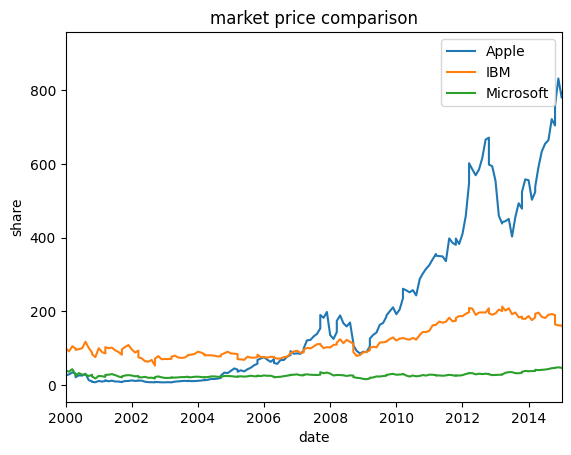

In [2]:
# This code cell is empty, ready for you to complete the above tasks in it
import numpy as np
data = np.genfromtxt('example.dat.txt', delimiter=',', skip_header=2)
a = data[:, 0]
b = data[:, 1]
c = data[:, 2]
d = data[:,3]
import matplotlib.pyplot as plt
plt.plot(a,b,label='Apple')
plt.plot(a,c,label='IBM')
plt.plot(a,d,label='Microsoft')
plt.xlabel('date')
plt.ylabel('share')
plt.title('market price comparison')
plt.xlim(2000,2015)
plt.legend()
plt.savefig('myfigure.png',dpi=300)
plt.show()






# Exporting Your Figure to use Elsewhere

Once you have produced a figure that you are happy with, you often want to export that figure to use in a report or paper. Both vector graphic files and bitmap files can be used. Vector files give the highest quality graphics, but are sometimes tricky to import into wordprocessors. In this course we **suggest using PNG** bitmap files with a high resolution, typically at least 300 dpi (dpi = dots per inch). These give good quality results, and are easy to use.

Please **DO NOT use use JPEG** images for scientific graphics; the lossy compression algorithm is good for photographs, but handles scientific images poorly.

To export a high quality PNG image, you can simply use the `savefig()` command.  For example:

```
plt.plot(x,y)
plt.savefig('myfigure.png',dpi=300)
plt.show()
```

Once you have run the `savefig()` command, you should find the file has been saved, and will appear in the files section of Colab (click the file icon on the left hand side of the webpage, if necessary).

Right click the file and choose download, to download a copy of the figure to your computer.

\


**Tasks:**

1. Export the figure you produced from `example.dat` as a PNG file and check that it appears in your Colab runtime.  To do this, **add your code in the previous code cell**.  Remember to call `savefig()` before `show()`, otherwise you will save a picture of a new, blank, figure.

2. Download the PNG file to your computer and check you can open it correctly.

\


# Your Second Piece of Work for Credit

Now you have finished working through the tasks in this Notebook, you are ready to move on to the piece of work for credit for this week. **Instructions are on the course Moodle site**, which explain what you need to do, and **how to submit your work**.

If you have enough time afterwards, **you should continue to work through the Additional Workbook** for Session 2.